# Proyecto Integrador de Ciencia de Datos e IA — Entregable 3
## Modelado avanzado, evaluación comparativa, optimización e interpretabilidad

**Universidad de La Salle — Maestría en Inteligencia Artificial — Ciencia de Datos**
Docente: Fabián Camilo Castro Riveros · Autor: Jairo Teófilo Araméndiz Pinzón

**Dataset:** *Medical Appointment No Shows* (Kaggle, `KaggleV2-May-2016.csv`, licencia CC BY-NC-SA 4.0).

Contenido:
1. Reproducción del preprocesamiento de la Fase 2 (misma limpieza, variables y partición).
2. **Clasificación** de la inasistencia: Random Forest y XGBoost con búsqueda de hiperparámetros por validación cruzada agrupada, y un **Perceptrón Multicapa (MLP) en PyTorch**.
3. **Regresión** de los días de espera: ElasticNet (regresión lineal regularizada) y XGBoost Regressor.
4. Comparación en validación, diagnóstico de sobreajuste y evaluación final única en prueba.
5. **Interpretabilidad** con SHAP.
6. **Clustering** de pacientes: K-Means (método del codo y coeficiente de silueta) y clustering jerárquico aglomerativo.
7. Exportación de los modelos para el tablero de la Fase 4.

Regla de evaluación: los hiperparámetros se eligen con validación cruzada dentro de entrenamiento, los modelos se comparan en validación y el conjunto de prueba se usa **una sola vez**, al final, con los modelos ya elegidos.

**Ejecución en Colab:** suba `KaggleV2-May-2016.csv` al panel de archivos o acepte la ventana de carga. Con el entorno gratuito de Colab (CPU) el cuaderno tarda alrededor de 10 a 15 minutos.

## 0. Librerías

In [1]:
import importlib, subprocess, sys
for paquete in ['xgboost', 'shap']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete], check=True)

import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, xgboost, torch

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, TargetEncoder
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, ElasticNet
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, r2_score, mean_squared_error, mean_absolute_error,
                             confusion_matrix, silhouette_score, adjusted_rand_score)
from scipy.stats import loguniform, uniform, randint
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
SEMILLA = 42
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
print('scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__, '| torch', torch.__version__)
RES = {}
T0 = time.time()

scikit-learn 1.9.1 | xgboost 3.4.1 | torch 2.15.0+cu132


## 1. Reproducción del preprocesamiento de la Fase 2
Se repite exactamente lo definido en el Entregable 2: eliminación de 6 registros imposibles, edades de 115 años tratadas como faltantes, 11 variables derivadas, partición 70/15/15 estratificada y agrupada por paciente con la misma semilla, y el mismo preprocesador ajustado solo con entrenamiento. Las justificaciones están en el cuaderno de la Fase 2.

In [2]:
NOMBRE = 'KaggleV2-May-2016.csv'
candidatos = [Path('../data') / NOMBRE, Path('data') / NOMBRE, Path(NOMBRE), Path('/content') / NOMBRE]
RUTA = next((p for p in candidatos if p.exists()), None)
if RUTA is None:
    try:
        from google.colab import files
        files.upload(); RUTA = Path(NOMBRE)
    except ImportError:
        raise FileNotFoundError(f'No se encontró {NOMBRE}')
MODELOS = RUTA.parent / 'modelos'; MODELOS.mkdir(exist_ok=True)

mapa = {'PatientId': 'id_paciente', 'AppointmentID': 'id_cita', 'Gender': 'sexo', 'ScheduledDay': 'fecha_agendamiento',
        'AppointmentDay': 'fecha_cita', 'Age': 'edad', 'Neighbourhood': 'barrio', 'Scholarship': 'bolsa_familia',
        'Hipertension': 'hipertension', 'Diabetes': 'diabetes', 'Alcoholism': 'alcoholismo', 'Handcap': 'discapacidad',
        'SMS_received': 'sms_recibido', 'No-show': 'no_asistio'}
df = pd.read_csv(RUTA).rename(columns=mapa)
df['id_paciente'] = df['id_paciente'].astype('int64').astype(str)
df['fecha_agendamiento'] = pd.to_datetime(df['fecha_agendamiento'], utc=True)
df['fecha_cita'] = pd.to_datetime(df['fecha_cita'], utc=True)
df['inasistencia'] = (df['no_asistio'] == 'Yes').astype(int)
df['dias_espera'] = (df['fecha_cita'].dt.normalize() - df['fecha_agendamiento'].dt.normalize()).dt.days

# Limpieza (Fase 2, sección 1)
df = df.loc[~((df.edad < 0) | (df.dias_espera < 0))].reset_index(drop=True)
df.loc[df.edad > 110, 'edad'] = np.nan

# Variables derivadas (Fase 2, sección 2)
df = df.sort_values(['id_paciente', 'fecha_cita', 'fecha_agendamiento']).reset_index(drop=True)
dias = {0: 'lunes', 1: 'martes', 2: 'miercoles', 3: 'jueves', 4: 'viernes', 5: 'sabado', 6: 'domingo'}
df['cita_mismo_dia'] = (df.dias_espera == 0).astype(int)
df['dia_semana_cita'] = df.fecha_cita.dt.dayofweek.map(dias)
df['dia_semana_agendamiento'] = df.fecha_agendamiento.dt.dayofweek.map(dias)
df['hora_agendamiento'] = df.fecha_agendamiento.dt.hour
df['n_condiciones_cronicas'] = df[['hipertension', 'diabetes', 'alcoholismo']].sum(axis=1)
df['grupo_etario'] = pd.cut(df.edad, [-1, 12, 18, 35, 60, 200], labels=['0-12', '13-18', '19-35', '36-60', '60+']).astype(str)
df.loc[df.edad.isna(), 'grupo_etario'] = np.nan
df['citas_mismo_dia'] = df.groupby(['id_paciente', 'fecha_cita']).id_cita.transform('count')
por_dia = df.groupby(['id_paciente', 'fecha_cita']).agg(n=('id_cita', 'count'), ina=('inasistencia', 'sum')).reset_index()
g = por_dia.groupby('id_paciente')
por_dia['citas_previas'] = g.n.cumsum() - por_dia.n
por_dia['inasistencias_previas'] = g.ina.cumsum() - por_dia.ina
df = df.merge(por_dia[['id_paciente', 'fecha_cita', 'citas_previas', 'inasistencias_previas']], on=['id_paciente', 'fecha_cita'], how='left')
df['tasa_inasistencia_previa'] = np.where(df.citas_previas > 0, df.inasistencias_previas / df.citas_previas.replace(0, 1), np.nan)
df['sexo_f'] = (df.sexo == 'F').astype(int)

# Partición (Fase 2, sección 4)
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEMILLA)
df['fold'] = -1
for k, (_, idx) in enumerate(sgkf.split(df, df.inasistencia, groups=df.id_paciente)):
    df.loc[idx, 'fold'] = k
df['conjunto'] = np.select([df.fold < 3, df.fold < 6], ['prueba', 'validacion'], 'entrenamiento')
assert df.groupby('id_paciente').conjunto.nunique().max() == 1
ent, val, pru = (df[df.conjunto == c].copy() for c in ['entrenamiento', 'validacion', 'prueba'])
print(df.groupby('conjunto').agg(citas=('id_cita', 'count'), pct_inasistencia=('inasistencia', 'mean')).round(4))

               citas  pct_inasistencia
conjunto                              
entrenamiento  77361            0.2019
prueba         16583            0.2020
validacion     16577            0.2018


In [3]:
# Preprocesador (Fase 2, sección 5)
class Winsorizador(BaseEstimator, TransformerMixin):
    def __init__(self, inf=0.0, sup=0.99):
        self.inf, self.sup = inf, sup
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lim_inf_ = np.nanquantile(X, self.inf, axis=0); self.lim_sup_ = np.nanquantile(X, self.sup, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lim_inf_, self.lim_sup_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)

def preprocesador(num, tasa, binarias, cat, alta, tipo_objetivo):
    pasos = [('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('win', Winsorizador(0, .99)), ('esc', StandardScaler())]), num),
             ('bin', 'passthrough', binarias),
             ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
             ('alta', TargetEncoder(target_type=tipo_objetivo, random_state=SEMILLA), alta)]
    if tasa:
        pasos.insert(1, ('tasa', Pipeline([('imp', SimpleImputer(strategy='mean', add_indicator=True)), ('esc', StandardScaler())]), tasa))
    return ColumnTransformer(pasos, verbose_feature_names_out=False)

# Clasificación
NUM = ['edad', 'dias_espera', 'hora_agendamiento', 'citas_previas', 'inasistencias_previas', 'citas_mismo_dia']
TASA = ['tasa_inasistencia_previa']
BIN = ['sexo_f', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'cita_mismo_dia', 'n_condiciones_cronicas']
CAT = ['dia_semana_cita', 'dia_semana_agendamiento', 'grupo_etario']
ALTA = ['barrio']
# Regresión (sin variables que revelan la espera)
NUM_R = ['edad', 'hora_agendamiento', 'citas_previas', 'inasistencias_previas', 'citas_mismo_dia']
BIN_R = ['sexo_f', 'bolsa_familia', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'n_condiciones_cronicas']
CAT_R = ['dia_semana_agendamiento', 'grupo_etario']

y_ent, y_val, y_pru = ent.inasistencia, val.inasistencia, pru.inasistencia
r_ent, r_val, r_pru = ent.dias_espera, val.dias_espera, pru.dias_espera
grupos_ent = ent.id_paciente
# Validación cruzada interna: 3 particiones estratificadas y agrupadas por paciente dentro de entrenamiento
CV = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
CV_R = GroupKFold(n_splits=3)
print('Entrenamiento:', ent.shape, '| validación:', val.shape, '| prueba:', pru.shape)

Entrenamiento: (77361, 29) | validación: (16577, 29) | prueba: (16583, 29)


## 2. Clasificación de la inasistencia

### 2.1 Referencia de la Fase 2
Se reentrena la regresión logística balanceada, que es el umbral mínimo que deben superar los modelos avanzados.

In [4]:
def metricas_clf(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {'exactitud': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred), 'F1': f1_score(y, pred), 'AUC_ROC': roc_auc_score(y, prob)}

base_log = Pipeline([('prep', preprocesador(NUM, TASA, BIN, CAT, ALTA, 'binary')),
                     ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))]).fit(ent, y_ent)
prob_val = {'Logística (baseline)': base_log.predict_proba(val)[:, 1]}
prob_ent = {'Logística (baseline)': base_log.predict_proba(ent)[:, 1]}
pd.DataFrame({'validación': metricas_clf(y_val, prob_val['Logística (baseline)'])}).T.round(3)

,exactitud,precision,recall,F1,AUC_ROC
validación,0.592,0.31,0.83,0.451,0.733


### 2.2 Random Forest y XGBoost con búsqueda de hiperparámetros
Se eligieron dos algoritmos de ensamble basados en árboles porque capturan interacciones y relaciones no lineales que el EDA sugirió (por ejemplo, el efecto del SMS cambia según la espera). KNN y SVM se descartaron por costo: con más de 77.000 registros de entrenamiento, KNN debe comparar cada predicción contra todo el conjunto y SVM con kernel escala de forma cuadrática.

- **Búsqueda:** `RandomizedSearchCV` con validación cruzada de 3 particiones estratificadas y **agrupadas por paciente** dentro de entrenamiento, métrica AUC-ROC.
- **Sin fuga:** el preprocesador va dentro del *pipeline*, así que en cada partición de la validación cruzada se vuelve a ajustar solo con los datos de esa partición.
- **Desbalance:** `class_weight='balanced_subsample'` en Random Forest y `scale_pos_weight` (negativos / positivos) en XGBoost.

In [5]:
ratio = (y_ent == 0).sum() / (y_ent == 1).sum()

rf = Pipeline([('prep', preprocesador(NUM, TASA, BIN, CAT, ALTA, 'binary')),
               ('m', RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=SEMILLA))])
espacio_rf = {'m__n_estimators': randint(150, 351), 'm__max_depth': randint(6, 19), 'm__min_samples_leaf': randint(5, 61),
              'm__max_features': ['sqrt', 0.3, 0.5], 'm__max_samples': [0.4, 0.6]}
t = time.time()
busq_rf = RandomizedSearchCV(rf, espacio_rf, n_iter=8, scoring='roc_auc', cv=CV, random_state=SEMILLA, n_jobs=1, return_train_score=True)
busq_rf.fit(ent, y_ent, groups=grupos_ent)
print(f'Random Forest: {time.time() - t:.0f} s | mejor AUC CV = {busq_rf.best_score_:.4f}'); print(busq_rf.best_params_)

xgb = Pipeline([('prep', preprocesador(NUM, TASA, BIN, CAT, ALTA, 'binary')),
                ('m', XGBClassifier(tree_method='hist', scale_pos_weight=ratio, eval_metric='auc', n_jobs=-1, random_state=SEMILLA))])
espacio_xgb = {'m__n_estimators': randint(200, 601), 'm__max_depth': randint(3, 9), 'm__learning_rate': loguniform(0.02, 0.2),
               'm__subsample': uniform(0.6, 0.4), 'm__colsample_bytree': uniform(0.5, 0.5),
               'm__min_child_weight': randint(1, 21), 'm__reg_lambda': loguniform(0.5, 20)}
t = time.time()
busq_xgb = RandomizedSearchCV(xgb, espacio_xgb, n_iter=15, scoring='roc_auc', cv=CV, random_state=SEMILLA, n_jobs=1, return_train_score=True)
busq_xgb.fit(ent, y_ent, groups=grupos_ent)
print(f'XGBoost: {time.time() - t:.0f} s | mejor AUC CV = {busq_xgb.best_score_:.4f}'); print(busq_xgb.best_params_)

RES['busqueda'] = {'rf': {'auc_cv': busq_rf.best_score_, 'params': busq_rf.best_params_},
                   'xgb': {'auc_cv': busq_xgb.best_score_, 'params': {k: float(v) for k, v in busq_xgb.best_params_.items()}}}

Random Forest: 125 s | mejor AUC CV = 0.7403
{'m__max_depth': 17, 'm__max_features': 'sqrt', 'm__max_samples': 0.4, 'm__min_samples_leaf': 16, 'm__n_estimators': 207}


XGBoost: 83 s | mejor AUC CV = 0.7418
{'m__colsample_bytree': np.float64(0.6783766633467947), 'm__learning_rate': np.float64(0.03819130560209075), 'm__max_depth': 6, 'm__min_child_weight': 13, 'm__n_estimators': 240, 'm__reg_lambda': np.float64(1.4914817179873872), 'm__subsample': np.float64(0.6661067756252009)}


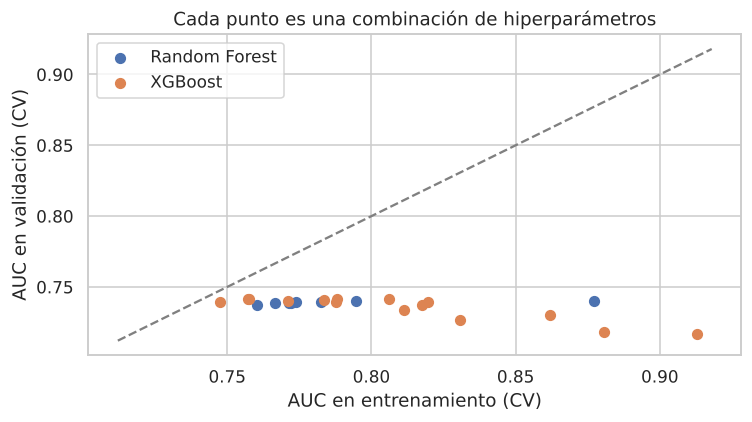

In [6]:
cv_res = pd.concat([pd.DataFrame(b.cv_results_).assign(modelo=n) for n, b in [('Random Forest', busq_rf), ('XGBoost', busq_xgb)]])
fig, ax = plt.subplots(figsize=(7, 4))
for n, d in cv_res.groupby('modelo'):
    ax.scatter(d.mean_train_score, d.mean_test_score, label=n, s=40)
lims = [cv_res[['mean_train_score', 'mean_test_score']].min().min() - .005, cv_res[['mean_train_score', 'mean_test_score']].max().max() + .005]
ax.plot(lims, lims, '--', color='grey'); ax.set_xlabel('AUC en entrenamiento (CV)'); ax.set_ylabel('AUC en validación (CV)')
ax.set_title('Cada punto es una combinación de hiperparámetros'); ax.legend(); plt.tight_layout(); plt.show()

El gráfico anterior es un primer diagnóstico de sobreajuste: los puntos lejos de la diagonal ajustan mucho mejor el entrenamiento que los datos que no vieron. Se prefiere la combinación con mejor AUC de validación, que en general tiene una brecha moderada.

In [7]:
mejores = {'Random Forest': busq_rf.best_estimator_, 'XGBoost': busq_xgb.best_estimator_}
for n, m in mejores.items():
    prob_val[n] = m.predict_proba(val)[:, 1]
    prob_ent[n] = m.predict_proba(ent)[:, 1]

### 2.3 Perceptrón Multicapa (MLP) en PyTorch
Red totalmente conectada sobre la misma matriz preprocesada (35 variables), ajustada solo con entrenamiento.

- Arquitectura: 35 → 64 → 32 → 1, activación ReLU, *batch normalization* y *dropout* de 0,3.
- Pérdida: `BCEWithLogitsLoss` con `pos_weight` = negativos / positivos para compensar el desbalance.
- Optimizador Adam (tasa 0,001, *weight decay* 1e-4), lotes de 512.
- Parada temprana: se detiene si la pérdida de validación no mejora en 6 épocas y se restauran los mejores pesos.

Épocas: 32 | mejor época: 28


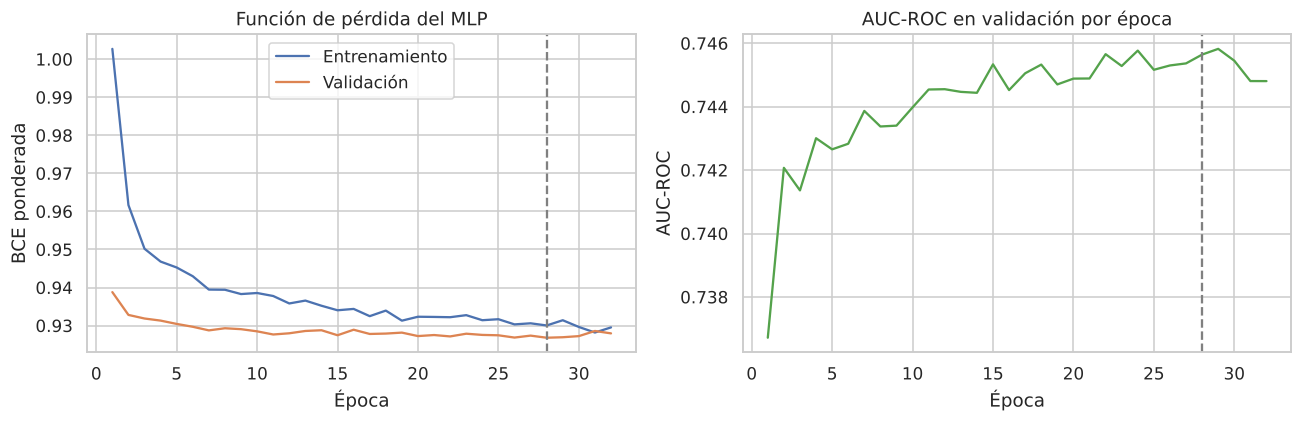

In [8]:
prep_mlp = preprocesador(NUM, TASA, BIN, CAT, ALTA, 'binary')
X_ent = prep_mlp.fit_transform(ent, y_ent).astype(np.float32)
X_val = prep_mlp.transform(val).astype(np.float32); X_pru = prep_mlp.transform(pru).astype(np.float32)
# Escalado adicional para las columnas binarias / codificadas (la red es sensible a la escala)
esc_mlp = StandardScaler().fit(X_ent)
X_ent_s, X_val_s, X_pru_s = (esc_mlp.transform(x).astype(np.float32) for x in (X_ent, X_val, X_pru))

class MLP(torch.nn.Module):
    def __init__(self, d):
        super().__init__()
        self.red = torch.nn.Sequential(
            torch.nn.Linear(d, 64), torch.nn.BatchNorm1d(64), torch.nn.ReLU(), torch.nn.Dropout(0.3),
            torch.nn.Linear(64, 32), torch.nn.BatchNorm1d(32), torch.nn.ReLU(), torch.nn.Dropout(0.3),
            torch.nn.Linear(32, 1))
    def forward(self, x):
        return self.red(x).squeeze(1)

torch.manual_seed(SEMILLA)
mlp = MLP(X_ent_s.shape[1])
perdida = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(ratio, dtype=torch.float32))
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
xe, ye = torch.tensor(X_ent_s), torch.tensor(y_ent.values, dtype=torch.float32)
xv, yv = torch.tensor(X_val_s), torch.tensor(y_val.values, dtype=torch.float32)
historia, mejor, paciencia, mejor_estado = [], np.inf, 0, None
for epoca in range(1, 61):
    mlp.train(); perm = torch.randperm(len(xe)); suma = 0.0
    for i in range(0, len(xe), 512):
        idx = perm[i:i + 512]
        opt.zero_grad(); l = perdida(mlp(xe[idx]), ye[idx]); l.backward(); opt.step()
        suma += l.item() * len(idx)
    mlp.eval()
    with torch.no_grad():
        lv = perdida(mlp(xv), yv).item(); auc_v = roc_auc_score(y_val, torch.sigmoid(mlp(xv)).numpy())
    historia.append({'epoca': epoca, 'perdida_ent': suma / len(xe), 'perdida_val': lv, 'auc_val': auc_v})
    if lv < mejor - 1e-4:
        mejor, paciencia, mejor_estado = lv, 0, {k: v.clone() for k, v in mlp.state_dict().items()}
    else:
        paciencia += 1
        if paciencia >= 6:
            break
mlp.load_state_dict(mejor_estado); mlp.eval()
hist = pd.DataFrame(historia)
mejor_epoca = int(hist.loc[hist.perdida_val.idxmin(), 'epoca'])
RES['mlp'] = {'epocas_entrenadas': int(hist.epoca.max()), 'mejor_epoca': mejor_epoca}
print(f'Épocas: {hist.epoca.max()} | mejor época: {mejor_epoca}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoca, hist.perdida_ent, label='Entrenamiento'); ax[0].plot(hist.epoca, hist.perdida_val, label='Validación')
ax[0].axvline(mejor_epoca, ls='--', color='grey'); ax[0].set_xlabel('Época'); ax[0].set_ylabel('BCE ponderada'); ax[0].set_title('Función de pérdida del MLP'); ax[0].legend()
ax[1].plot(hist.epoca, hist.auc_val, color='#54a24b'); ax[1].axvline(mejor_epoca, ls='--', color='grey')
ax[1].set_xlabel('Época'); ax[1].set_ylabel('AUC-ROC'); ax[1].set_title('AUC-ROC en validación por época')
plt.tight_layout(); plt.show()

with torch.no_grad():
    prob_val['MLP (PyTorch)'] = torch.sigmoid(mlp(xv)).numpy()
    prob_ent['MLP (PyTorch)'] = torch.sigmoid(mlp(xe)).numpy()

### 2.4 Comparación en validación y elección del umbral
Con `class_weight` y `pos_weight` las probabilidades quedan desplazadas hacia la clase positiva, así que el umbral 0,5 no es necesariamente el mejor. Para cada modelo se elige en **validación** el umbral que maximiza el F1 y ese mismo umbral se usa después en prueba.

In [9]:
def umbral_f1(y, prob):
    p, r, u = precision_recall_curve(y, prob)
    f1 = 2 * p * r / np.clip(p + r, 1e-9, None)
    return float(u[np.argmax(f1[:-1])])

umbrales, filas = {}, []
for n in prob_val:
    umbrales[n] = umbral_f1(y_val, prob_val[n])
    filas.append({'modelo': n, 'AUC_ent': roc_auc_score(y_ent, prob_ent[n]), **metricas_clf(y_val, prob_val[n], umbrales[n]), 'umbral': umbrales[n]})
comp_clf = pd.DataFrame(filas).set_index('modelo').sort_values('AUC_ROC', ascending=False)
comp_clf['brecha_AUC'] = comp_clf.AUC_ent - comp_clf.AUC_ROC
RES['comparacion_clf_validacion'] = comp_clf.round(4).to_dict('index')
comp_clf.round(3)

,AUC_ent,exactitud,precision,recall,F1,AUC_ROC,umbral,brecha_AUC
modelo,,,,,,,,
XGBoost,0.778,0.636,0.330,0.782,0.464,0.747,0.516,0.031
MLP (PyTorch),0.753,0.643,0.333,0.770,0.465,0.745,0.537,0.008
Random Forest,0.792,0.650,0.334,0.744,0.461,0.745,0.517,0.047
Logística (baseline),0.733,0.605,0.315,0.811,0.453,0.733,0.512,0.001


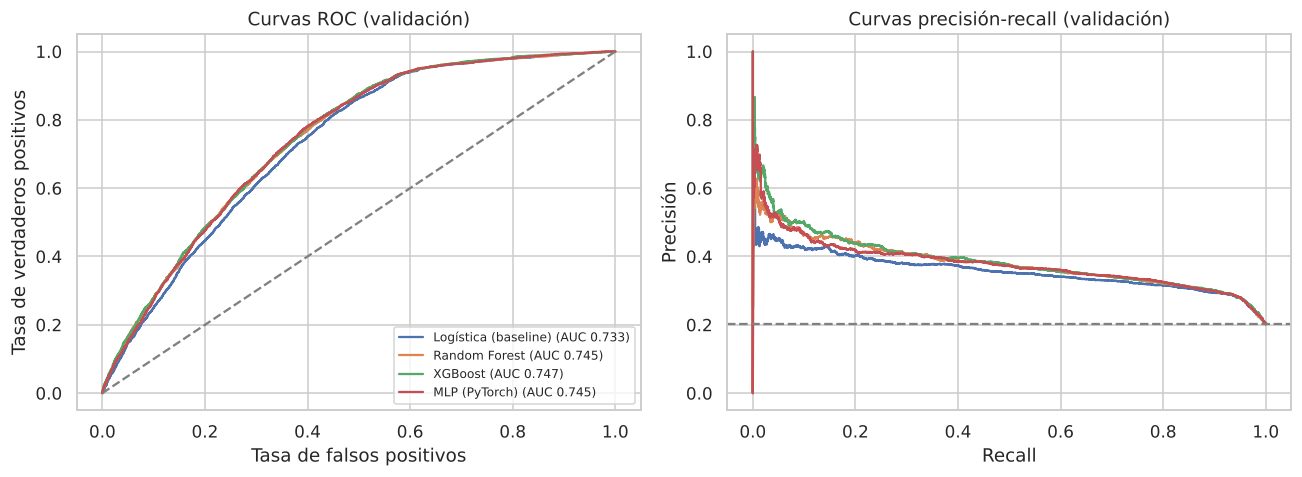

Modelo elegido por AUC-ROC en validación: XGBoost


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, p in prob_val.items():
    fpr, tpr, _ = roc_curve(y_val, p); ax[0].plot(fpr, tpr, label=f'{n} (AUC {roc_auc_score(y_val, p):.3f})')
    pr, rc, _ = precision_recall_curve(y_val, p); ax[1].plot(rc, pr, label=n)
ax[0].plot([0, 1], [0, 1], '--', color='grey'); ax[0].set_xlabel('Tasa de falsos positivos'); ax[0].set_ylabel('Tasa de verdaderos positivos'); ax[0].set_title('Curvas ROC (validación)'); ax[0].legend(fontsize=8)
ax[1].axhline(y_val.mean(), ls='--', color='grey'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precisión'); ax[1].set_title('Curvas precisión-recall (validación)')
plt.tight_layout(); plt.show()
MEJOR_CLF = comp_clf.index[0]
print('Modelo elegido por AUC-ROC en validación:', MEJOR_CLF)

## 3. Regresión de los días de espera
El objetivo es estimar cuántos días pasarán entre el agendamiento y la cita con la información disponible al momento de agendar. Se excluyen las variables que revelan la espera (SMS, cita del mismo día, día de la cita), como se justificó en la Fase 2.

- **ElasticNet:** regresión lineal con penalización combinada L1 y L2; se buscan `alpha` y `l1_ratio`.
- **XGBoost Regressor:** ensamble de árboles con búsqueda aleatoria de hiperparámetros.

Ambos con validación cruzada de 3 particiones agrupadas por paciente y métrica RMSE.

In [11]:
def metricas_reg(y, p):
    return {'R2': r2_score(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5, 'MAE': mean_absolute_error(y, p)}

lin = Pipeline([('prep', preprocesador(NUM_R, [], BIN_R, CAT_R, ALTA, 'continuous')), ('m', LinearRegression())]).fit(ent, r_ent)

en = Pipeline([('prep', preprocesador(NUM_R, [], BIN_R, CAT_R, ALTA, 'continuous')), ('m', ElasticNet(max_iter=5000, random_state=SEMILLA))])
busq_en = RandomizedSearchCV(en, {'m__alpha': loguniform(1e-3, 10), 'm__l1_ratio': uniform(0, 1)}, n_iter=15,
                             scoring='neg_root_mean_squared_error', cv=CV_R, random_state=SEMILLA, n_jobs=1, return_train_score=True)
busq_en.fit(ent, r_ent, groups=grupos_ent)
print('ElasticNet:', busq_en.best_params_, '| RMSE CV:', round(-busq_en.best_score_, 3))

xgbr = Pipeline([('prep', preprocesador(NUM_R, [], BIN_R, CAT_R, ALTA, 'continuous')),
                 ('m', XGBRegressor(tree_method='hist', n_jobs=-1, random_state=SEMILLA))])
espacio_xgbr = {'m__n_estimators': randint(200, 601), 'm__max_depth': randint(3, 9), 'm__learning_rate': loguniform(0.02, 0.2),
                'm__subsample': uniform(0.6, 0.4), 'm__colsample_bytree': uniform(0.5, 0.5),
                'm__min_child_weight': randint(1, 31), 'm__reg_lambda': loguniform(0.5, 20)}
t = time.time()
busq_xgbr = RandomizedSearchCV(xgbr, espacio_xgbr, n_iter=12, scoring='neg_root_mean_squared_error', cv=CV_R,
                               random_state=SEMILLA, n_jobs=1, return_train_score=True)
busq_xgbr.fit(ent, r_ent, groups=grupos_ent)
print(f'XGBoost Regressor: {time.time() - t:.0f} s |', busq_xgbr.best_params_, '| RMSE CV:', round(-busq_xgbr.best_score_, 3))

regs = {'Lineal múltiple (baseline)': lin, 'ElasticNet': busq_en.best_estimator_, 'XGBoost Regressor': busq_xgbr.best_estimator_}
filas = []
for n, m in regs.items():
    filas.append({'modelo': n, **{f'{k}_ent': v for k, v in metricas_reg(r_ent, m.predict(ent)).items()}, **metricas_reg(r_val, m.predict(val))})
comp_reg = pd.DataFrame(filas).set_index('modelo')[['R2', 'RMSE', 'MAE', 'R2_ent', 'RMSE_ent']]
RES['comparacion_reg_validacion'] = comp_reg.round(4).to_dict('index')
RES['elasticnet_params'] = {k: float(v) for k, v in busq_en.best_params_.items()}
comp_reg.round(3)

ElasticNet: {'m__alpha': np.float64(0.01474275315991467), 'm__l1_ratio': np.float64(0.3663618432936917)} | RMSE CV: 14.72


XGBoost Regressor: 53 s | {'m__colsample_bytree': np.float64(0.5979914312095727), 'm__learning_rate': np.float64(0.022195109122206198), 'm__max_depth': 7, 'm__min_child_weight': 16, 'm__n_estimators': 436, 'm__reg_lambda': np.float64(1.360465183078236), 'm__subsample': np.float64(0.9314950036607718)} | RMSE CV: 14.342


,R2,RMSE,MAE,R2_ent,RMSE_ent
modelo,,,,,
Lineal múltiple (baseline),0.079,14.594,10.574,0.075,14.701
ElasticNet,0.079,14.596,10.573,0.075,14.701
XGBoost Regressor,0.131,14.179,10.181,0.185,13.796


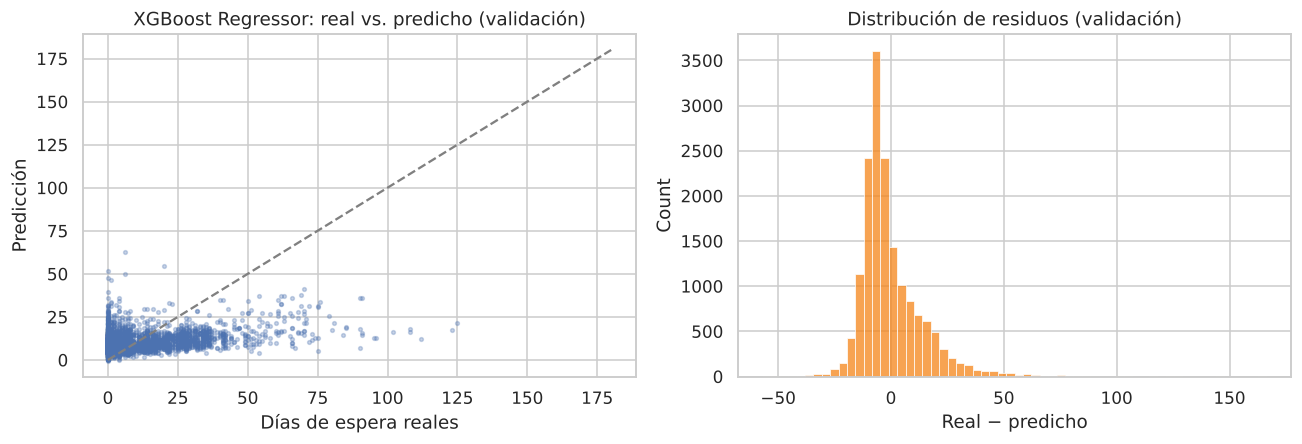

Modelo de regresión elegido: XGBoost Regressor


In [12]:
p_xgbr = busq_xgbr.best_estimator_.predict(val)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
m = np.random.RandomState(SEMILLA).choice(len(val), 4000, replace=False)
ax[0].scatter(r_val.values[m], p_xgbr[m], s=6, alpha=.3); ax[0].plot([0, 180], [0, 180], '--', color='grey')
ax[0].set_xlabel('Días de espera reales'); ax[0].set_ylabel('Predicción'); ax[0].set_title('XGBoost Regressor: real vs. predicho (validación)')
sns.histplot(r_val - p_xgbr, bins=60, ax=ax[1], color='#f58518'); ax[1].set_title('Distribución de residuos (validación)'); ax[1].set_xlabel('Real − predicho')
plt.tight_layout(); plt.show()
MEJOR_REG = comp_reg.R2.idxmax(); print('Modelo de regresión elegido:', MEJOR_REG)

## 4. Evaluación final en el conjunto de prueba
Se evalúan **una sola vez** los modelos ya elegidos, con los hiperparámetros y umbrales fijados en entrenamiento y validación.

In [13]:
prob_pru = {'Logística (baseline)': base_log.predict_proba(pru)[:, 1], 'Random Forest': mejores['Random Forest'].predict_proba(pru)[:, 1],
            'XGBoost': mejores['XGBoost'].predict_proba(pru)[:, 1]}
with torch.no_grad():
    prob_pru['MLP (PyTorch)'] = torch.sigmoid(mlp(torch.tensor(X_pru_s))).numpy()
final_clf = pd.DataFrame({n: metricas_clf(y_pru, p, umbrales[n]) for n, p in prob_pru.items()}).T.sort_values('AUC_ROC', ascending=False)
final_reg = pd.DataFrame({n: metricas_reg(r_pru, m.predict(pru)) for n, m in regs.items()}).T
RES['prueba_clf'] = final_clf.round(4).to_dict('index'); RES['prueba_reg'] = final_reg.round(4).to_dict('index')
print('CLASIFICACIÓN — prueba (umbral elegido en validación)'); display(final_clf.round(3))
print('REGRESIÓN — prueba'); display(final_reg.round(3))

CLASIFICACIÓN — prueba (umbral elegido en validación)


,exactitud,precision,recall,F1,AUC_ROC
XGBoost,0.628,0.323,0.770,0.455,0.740
Random Forest,0.645,0.330,0.735,0.455,0.739
MLP (PyTorch),0.633,0.324,0.756,0.454,0.738
Logística (baseline),0.604,0.313,0.806,0.451,0.729


REGRESIÓN — prueba


,R2,RMSE,MAE
Lineal múltiple (baseline),0.077,14.568,10.529
ElasticNet,0.077,14.568,10.528
XGBoost Regressor,0.138,14.074,10.052


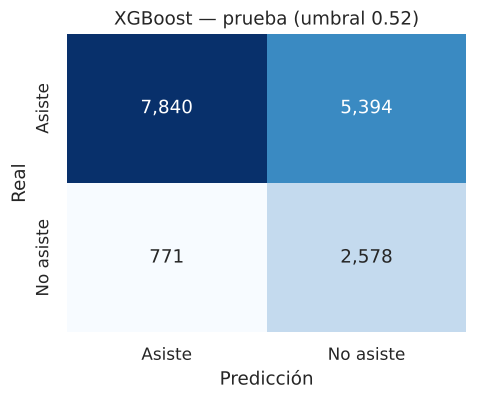

In [14]:
cm = confusion_matrix(y_pru, (prob_pru[MEJOR_CLF] >= umbrales[MEJOR_CLF]).astype(int))
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', cbar=False, ax=ax, xticklabels=['Asiste', 'No asiste'], yticklabels=['Asiste', 'No asiste'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.set_title(f'{MEJOR_CLF} — prueba (umbral {umbrales[MEJOR_CLF]:.2f})')
plt.tight_layout(); plt.show()
RES['matriz_confusion_prueba'] = cm.tolist()

## 5. Interpretabilidad con SHAP
Se calculan los valores SHAP del modelo XGBoost de clasificación sobre una muestra de 3.000 citas de validación. Cada valor indica cuánto empuja una variable la predicción de una cita hacia "no asiste" (positivo) o hacia "asiste" (negativo).

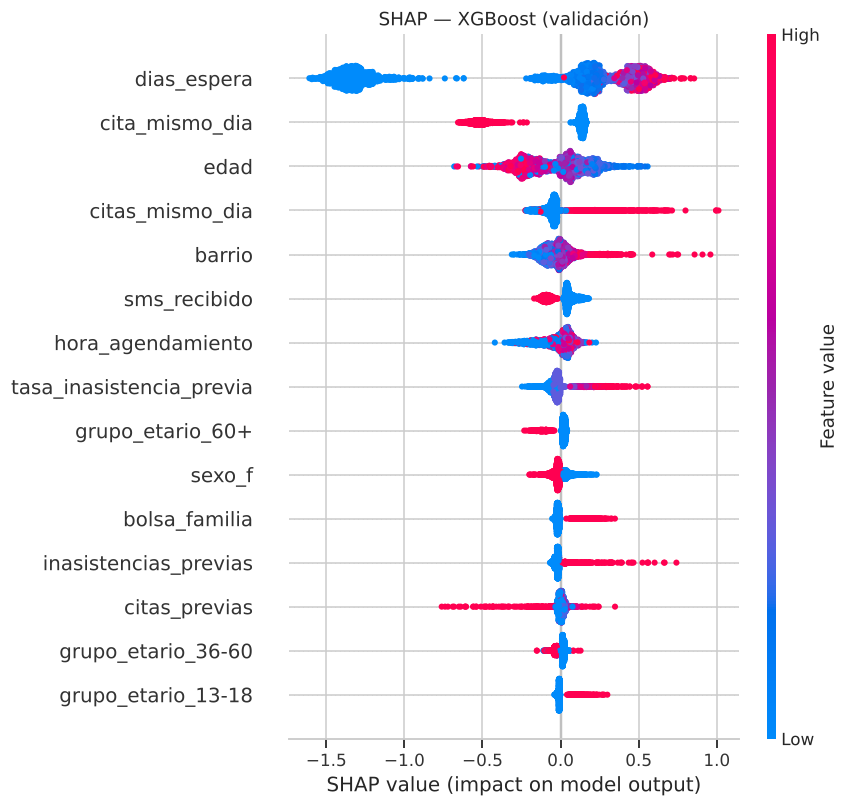

dias_espera                 0.6764
cita_mismo_dia              0.2720
edad                        0.1640
citas_mismo_dia             0.0962
barrio                      0.0756
sms_recibido                0.0703
hora_agendamiento           0.0699
tasa_inasistencia_previa    0.0604
grupo_etario_60+            0.0389
sexo_f                      0.0325
bolsa_familia               0.0321
inasistencias_previas       0.0319
citas_previas               0.0241
grupo_etario_36-60          0.0234
grupo_etario_13-18          0.0183
dtype: float32

In [15]:
import shap
mod_xgb = mejores['XGBoost']
nombres = mod_xgb.named_steps['prep'].get_feature_names_out()
muestra = val.sample(3000, random_state=SEMILLA)
Xm = pd.DataFrame(mod_xgb.named_steps['prep'].transform(muestra), columns=nombres)
try:
    sv = shap.TreeExplainer(mod_xgb.named_steps['m']).shap_values(Xm)
except Exception as e:  # compatibilidad de versiones: XGBoost calcula los mismos valores SHAP de forma nativa
    print('TreeExplainer no disponible con esta versión, se usa pred_contribs de XGBoost:', type(e).__name__)
    sv = mod_xgb.named_steps['m'].get_booster().predict(xgboost.DMatrix(Xm), pred_contribs=True)[:, :-1]
imp_shap = pd.Series(np.abs(sv).mean(0), index=nombres).sort_values(ascending=False)
RES['shap_top10'] = imp_shap.head(10).round(4).to_dict()
plt.figure(); shap.summary_plot(sv, Xm, max_display=15, show=False); plt.title('SHAP — XGBoost (validación)'); plt.tight_layout(); plt.show()
imp_shap.head(15).round(4)

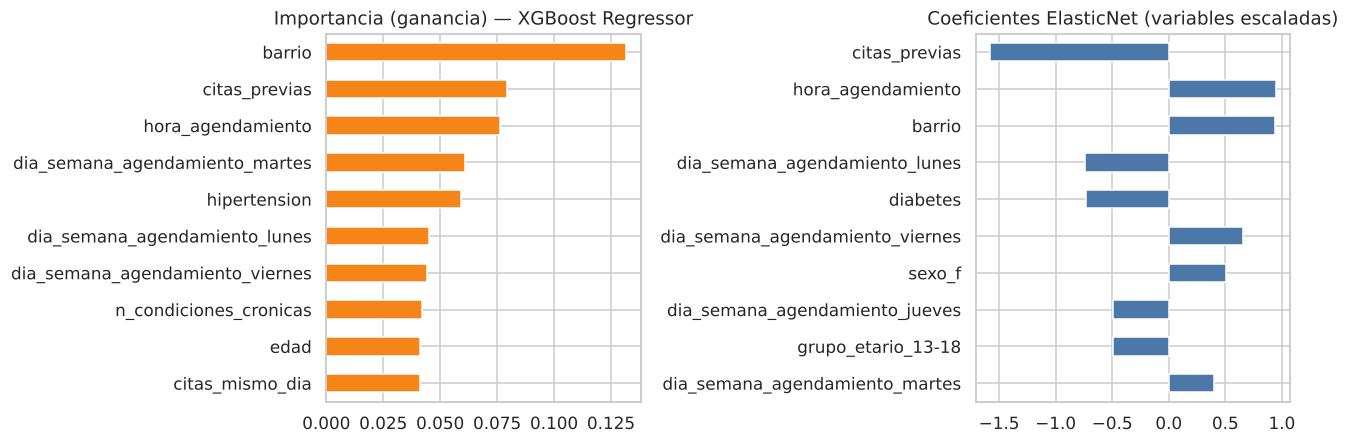

In [16]:
imp_reg = pd.Series(busq_xgbr.best_estimator_.named_steps['m'].feature_importances_,
                    index=busq_xgbr.best_estimator_.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False)
coef_en = pd.Series(busq_en.best_estimator_.named_steps['m'].coef_, index=busq_en.best_estimator_.named_steps['prep'].get_feature_names_out())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
imp_reg.head(10).iloc[::-1].plot.barh(ax=ax[0], color='#f58518'); ax[0].set_title('Importancia (ganancia) — XGBoost Regressor')
coef_en[coef_en.abs().sort_values(ascending=False).index[:10]].iloc[::-1].plot.barh(ax=ax[1], color='#4c78a8'); ax[1].set_title('Coeficientes ElasticNet (variables escaladas)')
plt.tight_layout(); plt.show()
RES['importancia_reg_top5'] = imp_reg.head(5).round(4).to_dict()
RES['elasticnet_coef_cero'] = int((coef_en == 0).sum())

## 6. Clustering de pacientes
Se usa la matriz de pacientes preparada en la Fase 2: 6 variables agregadas por paciente (edad, número de citas, tasa de inasistencia, espera media, condiciones crónicas y proporción de citas con SMS), con `log(1 + x)` en los conteos y `RobustScaler`.

### 6.1 K-Means: número de clústeres
Se evalúa K entre 2 y 10 con la inercia (método del codo) y el coeficiente de silueta. La silueta se calcula sobre una muestra fija de 10.000 pacientes por costo computacional.

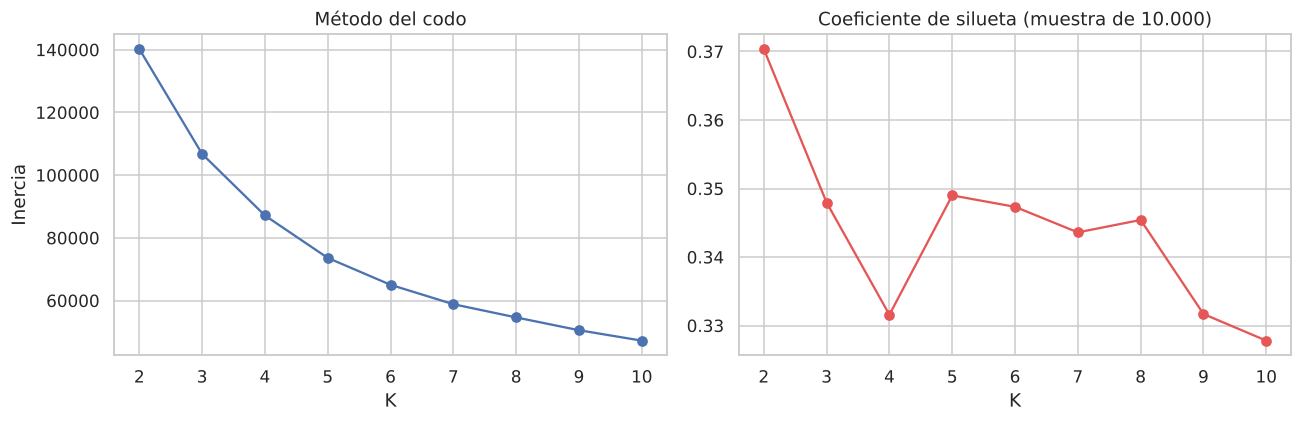

,inercia,silueta,reduccion_inercia_%
K,,,
2,140231.973,0.370,NaN
3,106764.084,0.348,23.866
4,87132.048,0.332,18.388
5,73597.748,0.349,15.533
6,65018.019,0.347,11.658
7,58829.349,0.344,9.518
8,54614.362,0.345,7.165
9,50530.927,0.332,7.477
10,47202.889,0.328,6.586


In [17]:
pac = df.groupby('id_paciente').agg(edad=('edad', 'median'), n_citas=('id_cita', 'count'), tasa_inasistencia=('inasistencia', 'mean'),
                                    espera_media=('dias_espera', 'mean'), n_condiciones_cronicas=('n_condiciones_cronicas', 'max'),
                                    prop_sms=('sms_recibido', 'mean'), bolsa_familia=('bolsa_familia', 'max'))
pac['edad'] = pac.edad.fillna(pac.edad.median())
pac['log_n_citas'] = np.log1p(pac.n_citas); pac['log_espera_media'] = np.log1p(pac.espera_media)
VARS_CLUSTER = ['edad', 'log_n_citas', 'tasa_inasistencia', 'log_espera_media', 'n_condiciones_cronicas', 'prop_sms']
esc_cl = RobustScaler().fit(pac[VARS_CLUSTER])
Xc = esc_cl.transform(pac[VARS_CLUSTER])
idx_m = np.random.RandomState(SEMILLA).choice(len(Xc), 10000, replace=False)

filas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xc)
    filas.append({'K': k, 'inercia': km.inertia_, 'silueta': silhouette_score(Xc[idx_m], km.labels_[idx_m])})
codo = pd.DataFrame(filas).set_index('K')
codo['reduccion_inercia_%'] = -codo.inercia.pct_change() * 100
RES['codo'] = codo.round(4).to_dict('index')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(codo.index, codo.inercia, 'o-'); ax[0].set_title('Método del codo'); ax[0].set_xlabel('K'); ax[0].set_ylabel('Inercia')
ax[1].plot(codo.index, codo.silueta, 'o-', color='#e45756'); ax[1].set_title('Coeficiente de silueta (muestra de 10.000)'); ax[1].set_xlabel('K')
plt.tight_layout(); plt.show()
codo.round(3)

**Regla de elección de K.** Se descarta K = 2 aunque suele tener la silueta más alta: con dos grupos, K-Means separa casi exclusivamente a los pacientes que faltaron de los que asistieron (la tasa de inasistencia de quien tiene una sola cita vale 0 o 1), lo que repite la variable objetivo de la clasificación y no aporta perfiles nuevos. Entre K ≥ 3 se toma el de mayor silueta entre los valores que todavía reducen la inercia en al menos 10 % respecto a K − 1, es decir, antes de que la curva del codo se aplane.

In [18]:
km2 = KMeans(n_clusters=2, n_init=10, random_state=SEMILLA).fit(Xc)
print('Con K = 2, tasa de inasistencia media por grupo:', pac.groupby(km2.labels_).tasa_inasistencia.mean().round(3).to_dict())
elegibles = codo[(codo.index >= 3) & (codo['reduccion_inercia_%'] >= 10)]
K = int(elegibles.silueta.idxmax())
km = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(Xc)
pac['cluster_kmeans'] = km.labels_
RES['K'] = K; RES['silueta_kmeans'] = float(silhouette_score(Xc[idx_m], km.labels_[idx_m]))
print(f'K elegido = {K} | silueta = {RES["silueta_kmeans"]:.3f}')

Con K = 2, tasa de inasistencia media por grupo: {0: 0.802, 1: 0.021}


K elegido = 5 | silueta = 0.349


### 6.2 Segundo algoritmo: clustering jerárquico aglomerativo (Ward)
El clustering aglomerativo necesita memoria cuadrática en el número de puntos, así que se aplica a la misma muestra de 10.000 pacientes con el mismo K. Se compara con K-Means mediante la silueta y el índice de Rand ajustado (ARI), que mide cuánto coinciden las dos particiones (1 = idénticas, 0 = coincidencia al azar).

In [19]:
agl = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(Xc[idx_m])
RES['silueta_jerarquico'] = float(silhouette_score(Xc[idx_m], agl.labels_))
RES['ARI_kmeans_vs_jerarquico'] = float(adjusted_rand_score(km.labels_[idx_m], agl.labels_))
print(f"Silueta K-Means (muestra): {RES['silueta_kmeans']:.3f} | Silueta jerárquico: {RES['silueta_jerarquico']:.3f} | ARI: {RES['ARI_kmeans_vs_jerarquico']:.3f}")

Silueta K-Means (muestra): 0.349 | Silueta jerárquico: 0.327 | ARI: 0.651


### 6.3 Perfiles de los segmentos

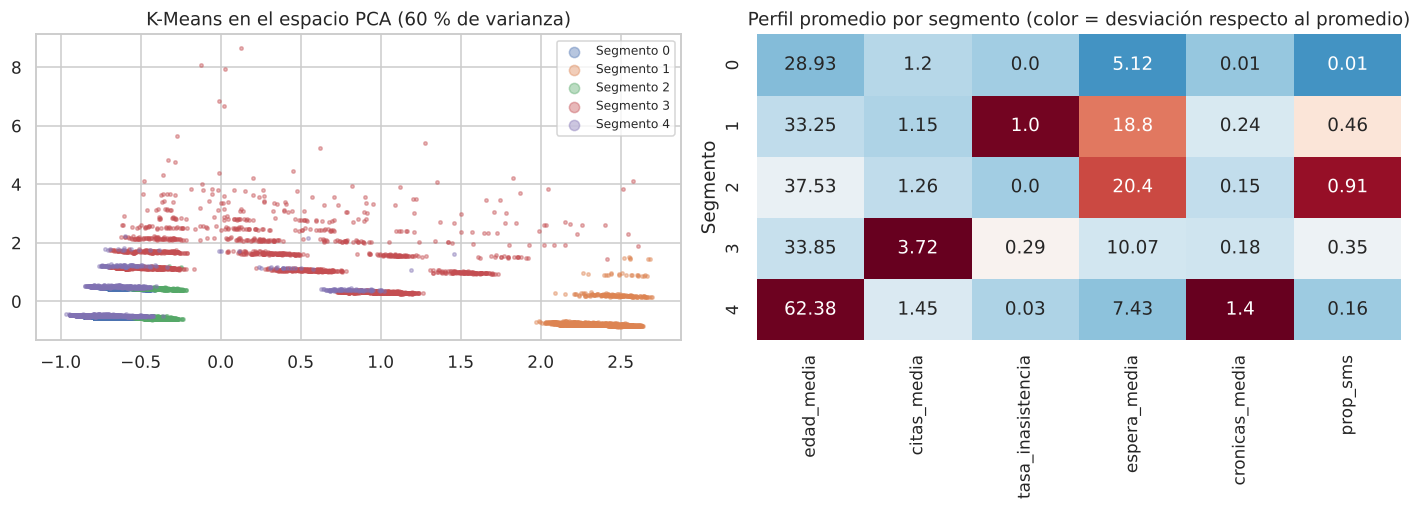

,pacientes,edad_media,citas_media,tasa_inasistencia,espera_media,cronicas_media,prop_sms,pct_bolsa_familia,pct_pacientes,inasistencia_citas_%
cluster_kmeans,,,,,,,,,,
0,20677,28.93,1.20,0.00,5.12,0.01,0.01,0.09,33.19,0.00
1,8117,33.25,1.15,1.00,18.80,0.24,0.46,0.10,13.03,100.00
2,11759,37.53,1.26,0.00,20.40,0.15,0.91,0.08,18.88,0.00
3,13283,33.85,3.72,0.29,10.07,0.18,0.35,0.11,21.32,25.09
4,8462,62.38,1.45,0.03,7.43,1.40,0.16,0.07,13.58,4.87


In [20]:
perfil = pac.groupby('cluster_kmeans').agg(pacientes=('edad', 'size'), edad_media=('edad', 'mean'), citas_media=('n_citas', 'mean'),
                                           tasa_inasistencia=('tasa_inasistencia', 'mean'), espera_media=('espera_media', 'mean'),
                                           cronicas_media=('n_condiciones_cronicas', 'mean'), prop_sms=('prop_sms', 'mean'),
                                           pct_bolsa_familia=('bolsa_familia', 'mean'))
perfil['pct_pacientes'] = perfil.pacientes / perfil.pacientes.sum() * 100
# Inasistencia a nivel de cita para cada segmento
citas_cl = df.merge(pac[['cluster_kmeans']], left_on='id_paciente', right_index=True)
perfil['inasistencia_citas_%'] = citas_cl.groupby('cluster_kmeans').inasistencia.mean() * 100
RES['perfiles'] = perfil.round(3).to_dict('index')

pca = PCA(n_components=2, random_state=SEMILLA).fit(Xc)
P = pca.transform(Xc[idx_m])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for c in range(K):
    s = km.labels_[idx_m] == c; ax[0].scatter(P[s, 0], P[s, 1], s=5, alpha=.4, label=f'Segmento {c}')
ax[0].set_title(f'K-Means en el espacio PCA ({pca.explained_variance_ratio_.sum() * 100:.0f} % de varianza)'); ax[0].legend(markerscale=3, fontsize=8)
z = (perfil[['edad_media', 'citas_media', 'tasa_inasistencia', 'espera_media', 'cronicas_media', 'prop_sms']])
sns.heatmap((z - z.mean()) / z.std(), annot=z.round(2), fmt='', cmap='RdBu_r', center=0, ax=ax[1], cbar=False)
ax[1].set_title('Perfil promedio por segmento (color = desviación respecto al promedio)'); ax[1].set_ylabel('Segmento')
plt.tight_layout(); plt.show()
perfil.round(2)

La interpretación de cada segmento y su uso práctico para la política de recordatorios se presenta en la síntesis final, a partir de la tabla anterior.

## 7. Exportación de modelos para el tablero (Fase 4)

In [21]:
joblib.dump(mejores['XGBoost'], MODELOS / 'clasificador_xgboost.joblib')
joblib.dump(busq_xgbr.best_estimator_, MODELOS / 'regresor_xgboost.joblib')
joblib.dump({'scaler': esc_cl, 'kmeans': km, 'variables': VARS_CLUSTER, 'pca': pca}, MODELOS / 'clustering.joblib')
torch.save({'estado': mlp.state_dict(), 'd': X_ent_s.shape[1]}, MODELOS / 'mlp.pt')
pac.to_csv(MODELOS / 'pacientes_segmentados.csv')
RES['umbral_xgboost'] = umbrales['XGBoost']
RES['tiempo_total_min'] = (time.time() - T0) / 60
(MODELOS / 'resultados_fase3.json').write_text(json.dumps(RES, indent=2, ensure_ascii=False, default=str))
print(f"Tiempo total: {RES['tiempo_total_min']:.1f} min | archivos:", sorted(p.name for p in MODELOS.iterdir()))

Tiempo total: 6.3 min | archivos: ['clasificador_xgboost.joblib', 'clustering.joblib', 'mlp.pt', 'pacientes_segmentados.csv', 'regresor_xgboost.joblib', 'resultados_fase3.json']


## 8. Síntesis

### Clasificación de la inasistencia
| Modelo | AUC-ROC validación | AUC-ROC prueba | F1 prueba | Recall prueba | Brecha AUC entrenamiento − validación |
|---|---|---|---|---|---|
| XGBoost | 0,747 | **0,740** | 0,455 | 0,770 | 0,031 |
| Random Forest | 0,745 | 0,739 | 0,455 | 0,735 | 0,047 |
| MLP (PyTorch) | 0,745 | 0,738 | 0,454 | 0,756 | 0,008 |
| Logística (baseline) | 0,733 | 0,729 | 0,451 | 0,806 | 0,001 |

- Los tres modelos avanzados superan al baseline en AUC-ROC y F1, tanto en validación como en prueba. Se cumple el objetivo específico 1 (AUC-ROC ≥ 0,70 y F1 superior al baseline). La ganancia es modesta (alrededor de 0,01 de AUC), lo que indica que buena parte de la señal ya era capturable con un modelo lineal sobre las variables construidas en la Fase 2.
- Se elige **XGBoost** por tener el mejor AUC en validación y en prueba, con una brecha de sobreajuste menor que la de Random Forest. El MLP es el que menos sobreajusta (brecha 0,008). En su curva de pérdida, la validación queda por debajo del entrenamiento porque el *dropout* solo está activo al entrenar; no es una señal de error.
- Con el umbral de 0,52 elegido en validación, XGBoost detecta el 77 % de las inasistencias en prueba (2.578 de 3.349), a cambio de 5.394 falsas alarmas. Para una política de recordatorios esto es aceptable, porque un mensaje adicional a quien sí iba a asistir tiene un costo bajo.
- **SHAP** confirma los hallazgos del EDA: los días de espera son la variable de mayor peso, las citas del mismo día reducen el riesgo, la edad avanzada lo reduce y el historial de inasistencias lo aumenta. Una vez el modelo controla la espera, haber recibido SMS **reduce** la probabilidad de inasistencia, en línea con el análisis estratificado del Entregable 1.

### Regresión de los días de espera
| Modelo | R² validación | R² prueba | RMSE prueba | MAE prueba |
|---|---|---|---|---|
| XGBoost Regressor | 0,131 | **0,138** | 14,07 | 10,05 |
| ElasticNet | 0,079 | 0,077 | 14,57 | 10,53 |
| Lineal múltiple (baseline) | 0,079 | 0,077 | 14,57 | 10,53 |

- XGBoost casi duplica el R² del modelo lineal, pero el poder explicativo sigue siendo bajo: el error medio absoluto es de unos 10 días. ElasticNet no mejora a la regresión lineal porque la regularización elegida es débil (`alpha` ≈ 0,015) y el problema no es de sobreajuste sino de falta de información: el dataset no incluye especialidad, profesional ni disponibilidad de agenda, que son los determinantes reales de la espera. El barrio, como aproximación de la unidad de atención, es la variable más importante del regresor.
- La brecha de R² entre entrenamiento (0,185) y validación (0,131) muestra un sobreajuste moderado en XGBoost, controlado por la búsqueda de hiperparámetros.

### Segmentación de pacientes (K-Means, K = 5)
| Segmento | % pacientes | Perfil | Inasistencia | Uso práctico |
|---|---|---|---|---|
| 0 | 33 % | Jóvenes (29 años en promedio), una cita, espera corta (5 días), casi sin SMS | 0 % | No requieren recordatorio |
| 1 | 13 % | Una cita, espera larga (19 días), menos de la mitad recibió SMS | 100 % | Grupo prioritario: confirmar la cita y ofrecer una fecha más cercana |
| 2 | 19 % | Una cita, espera larga (20 días), 91 % recibió SMS | 0 % | Evidencia de que el recordatorio acompaña la asistencia en esperas largas |
| 3 | 21 % | Usuarios frecuentes (3,7 citas), espera media | 25 % | Seguimiento del historial: alertar cuando acumulan inasistencias |
| 4 | 14 % | Adultos mayores (62 años), con condiciones crónicas | 5 % | Pacientes de control, alta adherencia |

- La elección de K = 5 combina el codo y la silueta (0,349). K = 2 se descartó porque solo separa a quienes faltaron de quienes asistieron. El clustering jerárquico de Ward obtiene una silueta similar (0,327) y coincide en buena medida con K-Means (ARI = 0,65), lo que da estabilidad a los segmentos.
- Los segmentos incluyen la tasa de inasistencia histórica, así que son una **descripción retrospectiva** de la población y no un predictor. La comparación entre los segmentos 1 y 2, que tienen perfiles parecidos (una cita, espera de unos 20 días) y se diferencian sobre todo en la cobertura de SMS y en el resultado, refuerza la hipótesis de que los recordatorios son más útiles en las citas lejanas. Este es el resultado que conecta directamente con la política de recordatorios de AgendamientoIA.

### Limitaciones
Los datos cubren seis semanas de citas en una ciudad brasileña y no incluyen especialidad ni canal de agendamiento. Los efectos del SMS son asociaciones observacionales, no causales: el envío no fue aleatorio.
